#Trabajo Principal

**Definición de vectores de tiempo y generación de la señal**

Para este ejercicio, vamos a generar una señal compuesta por senos de 1 Hz, 3 Hz, 4 Hz y 9 Hz. Dado que nuestra frecuencia máxima es 9 Hz, aplicando el criterio de Nyquist necesitamos una frecuencia de muestreo mayor a 18 Hz. Elegiremos una $f_s$ de 25 Hz para tener un buen margen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de parámetros
pi = np.pi
tmax = 10.001 # [s] tiempo máximo

# Frecuencia de muestreo (Nyquist: fs > 2 * fmax -> fs > 2 * 9 = 18)
fs = 25 # [Hz]
dt = 1/fs # [s]

# Vectores de tiempo
t = np.arange(0, tmax, 0.001) # Semicontinuo
ts = np.arange(0, tmax, dt)   # Discreto (muestreado)

# 2. Generación de la señal (1 Hz, 3 Hz, 4 Hz, 9 Hz con distintas amplitudes y desfases)
signal_c = (2 * np.sin(2*pi*1*t) +
            1.5 * np.sin(2*pi*3*t + pi/4) +
            1 * np.sin(2*pi*4*t) +
            0.5 * np.sin(2*pi*9*t - pi/2))

signal_s = (2 * np.sin(2*pi*1*ts) +
            1.5 * np.sin(2*pi*3*ts + pi/4) +
            1 * np.sin(2*pi*4*ts) +
            0.5 * np.sin(2*pi*9*ts - pi/2))

**Recuperación de la señal**

Aplicamos la fórmula de interpolación Whittaker-Shannon para reconstruir la señal original a partir de las muestras discretas.

In [2]:
# Inicializamos el vector de la señal recuperada
signal_rec_tot = np.zeros(len(t))

# Reconstrucción (Aquí aparecerán los Warnings por división entre cero esperados)
for i in range(len(t)):
    for j in range(len(ts)):
        # Fórmula de Whittaker-Shannon
        signal_rec_tot[i] += signal_s[j] * (np.sin(pi*(fs*t[i]-j)) / (pi*(fs*t[i]-j)))

/tmp/ipykernel_14565/3308546400.py:8: RuntimeWarning: invalid value encountered in scalar divide
  signal_rec_tot[i] += signal_s[j] * (np.sin(pi*(fs*t[i]-j)) / (pi*(fs*t[i]-j)))


**Representación gráfica**

Comparamos visualmente las señales obtenidas.

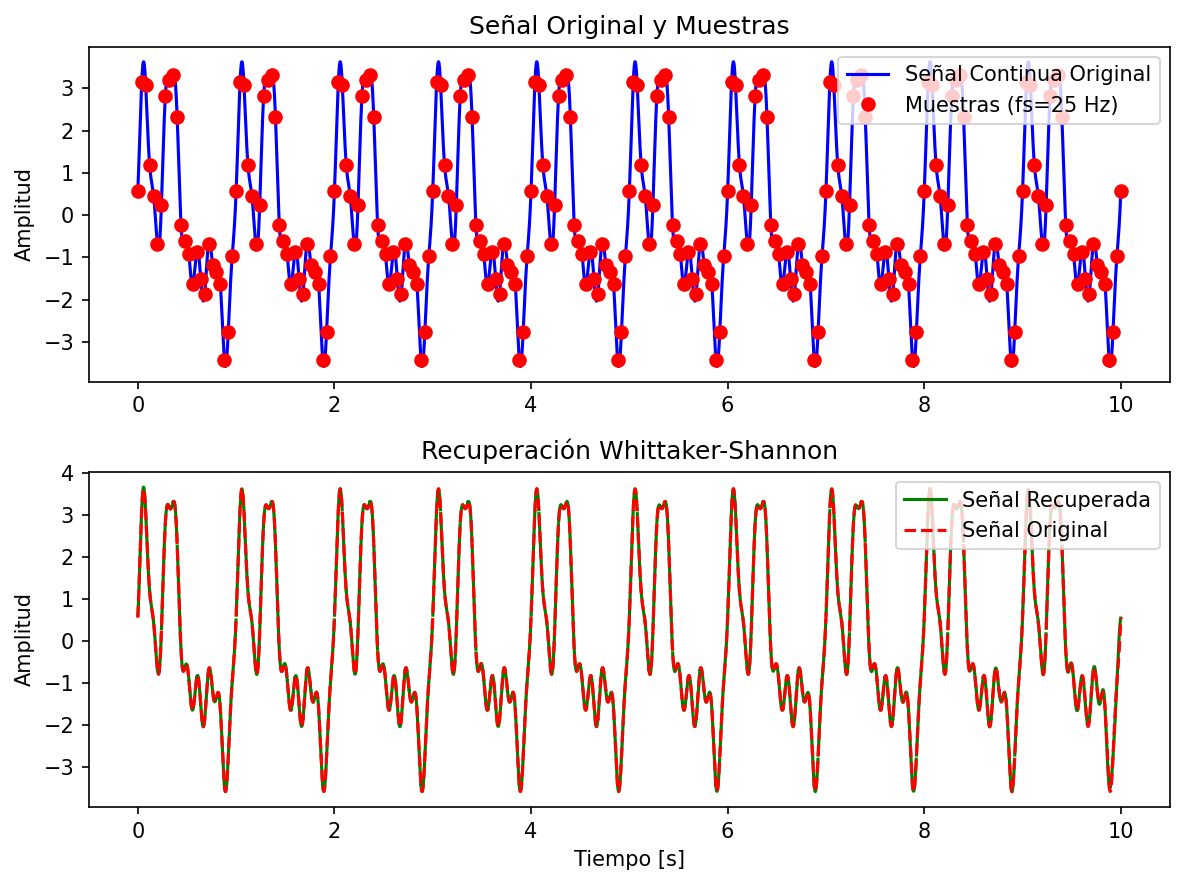

In [3]:
fig, axs = plt.subplots(2, figsize=(8,6), dpi=150)

# Gráfica superior: Señal continua y muestras
axs[0].plot(t, signal_c, 'b-', label='Señal Continua Original')
axs[0].plot(ts, signal_s, 'ro', label='Muestras (fs=25 Hz)')
axs[0].set(ylabel='Amplitud', title='Señal Original y Muestras')
axs[0].legend(loc='upper right')

# Gráfica inferior: Señal recuperada vs original
axs[1].plot(t, signal_rec_tot, 'g-', label='Señal Recuperada')
axs[1].plot(t, signal_c, 'r--', label='Señal Original')
axs[1].set(xlabel='Tiempo [s]', ylabel='Amplitud', title='Recuperación Whittaker-Shannon')
axs[1].legend(loc='upper right')

fig.tight_layout()
plt.show()

**1. ¿Ha funcionado la interpolación? ¿Hemos obtenido una señal reconstruida igual que la original?**

Sí, la interpolación ha funcionado perfectamente. Hemos obtenido una señal reconstruida que es prácticamente idéntica a la señal semicontinua original.

**2. ¿Por qué ha sido posible esto? ¿Qué se debe cumplir para que esto sea posible?**

Porque se cumple el criterio de Nyquist-Shannon. Para poder reconstruir una señal sin pérdida de información, la frecuencia de muestreo debe ser estrictamente mayor que el doble de la frecuencia máxima presente en la señal ($f_s > 2 \cdot f_{max}$). En el ejemplo inicial de la práctica, la frecuencia máxima era 3 Hz y la de muestreo era 10 Hz, cumpliendo holgadamente el criterio ($10 > 6$).

**¿Habría sido posible con fs = 5 Hz?**

No. Con una frecuencia de muestreo de 5 Hz no habría sido posible reconstruir la señal original. Como la señal tenía un componente de 3 Hz, necesitaríamos al menos una $f_s > 6$ Hz.

**¿Y si la señal tuviera un seno de 6 Hz?**

Si la señal hubiese tenido un seno de 6 Hz, nuestra $f_{max}$ sería 6 Hz. Por tanto, necesitaríamos una frecuencia de muestreo $f_s > 12$ Hz. Con los 10 Hz originales, tampoco habría sido posible y la señal sufriría distorsión.

#Trabajo Opcional

**1. ¿Qué hace exactamente la instrucción fig.tight_layout()?**

Esta instrucción ajusta automáticamente los parámetros de las subgráficas (márgenes y espacios entre ellas) para que ocupen el área de la figura de forma óptima. Su principal función es evitar que los títulos, las etiquetas de los ejes o los números se solapen entre sí.

**2. Ejecuta dos veces esta celda, una con esta instrucción comentada (sin que se ejecute) y otra con esta instrucción activa. ¿Cuáles son las diferencias?
¿Merece la pena usar esta instrucción?**

Al ejecutar sin la instrucción, los números del eje X de la gráfica superior se "pisan" con el título de la gráfica inferior, creando un resultado desordenado. Al activar la instrucción, la librería crea automáticamente el espacio perfecto entre ambas. Sí, merece mucho la pena usarla siempre que tengamos varias subgráficas para garantizar una visualización limpia y profesional.

**Solución al Warning de la función sinc(x) cuando x = 0:** El problema matemático radica en que el límite de $\frac{\sin(\pi x)}{\pi x}$ cuando $x$ tiende a 0 es 1. Sin embargo, Python intenta evaluar primero el denominador y detecta una división por cero antes de aplicar cualquier límite lógico, lanzando el aviso.  Para arreglarlo, he modificado el bloque de la matriz de reconstrucción añadiendo una estructura condicional if/else. De esta manera, cuando el argumento de la función sinc sea 0, le asignamos directamente el valor 1, evitando la operación problemática.

In [4]:
# Arreglo de la Matriz de Reconstrucción
matrix_rec_fixed = np.zeros((len(signal_s), len(t)))

for i in range(len(signal_s)):
    for j in range(len(t)):

        # Calculamos el argumento de la función sinc (sin multiplicar por pi todavía)
        x = fs * t[j] - i

        # Condición para evitar la división por cero
        if x == 0:
            sinc_val = 1.0 # El límite matemático cuando el argumento es 0
        else:
            sinc_val = np.sin(pi * x) / (pi * x)

        matrix_rec_fixed[i][j] = signal_s[i] * sinc_val

print("Matriz calculada con éxito y sin Warnings de división por cero.")

Matriz calculada con éxito y sin Warnings de división por cero.


**¿Ha habido algún cambio en los resultados? ¿Ha merecido la pena?**

Visualmente y numéricamente los resultados de la señal interpolada no muestran cambios drásticos porque un único punto nulo no suele destrozar toda la gráfica (especialmente en vectores tan grandes). Sin embargo, sí ha merecido la pena. Ahora el código es mucho más robusto computacionalmente, se ejecuta de manera limpia sin alertas y es matemáticamente fiel a la definición completa de la función sinc.